# Assignment 7

In [1]:
ROLL_NO = 1024170164         # <-- your full roll number
NAME = "Kanan"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170164   Name: Kanan   Fingerprint: BCE9DC8C   Tickets: 16

Ticket_ID                                                                                     Ticket_Text
      T01                       Projector keeps disconnecting since yesterday. Is there another solution?
      T02 I couldn't connect to the server when connected to campus Wi-Fi. The same problem occurs again.
      T03                                                     I can't login and I didn't change anything.
      T04                                                           I need Windows 11 by 5.30 p.m. today.
      T05           I couldn't connect to the Wi-Fi when I use mobile hotspot. I don't know what changed.
      T06                   Printer keeps asking for login during the lab. The same problem occurs again.
      T07                 WiFi is not working after resetting my password. The same problem occurs again.
      T08                                   The printer is running slowly. 

## Q1. Preprocessing

Run `process_ticket()` on every ticket. Create one table containing, for each ticket:

- number of sentences
- number of tokens
- number of punctuation tokens
- number of stopwords
- number of unique tokens
- number of final tokens

Add a total row for the count-based columns. For one selected ticket, display the actual tokens, punctuation tokens, stopwords and final tokens.

In [5]:
df, focus, fp = generate_dataset(ROLL_NO)
print("Fingerprint:", fp)

rows = []
for tid, text in zip(df.Ticket_ID, df.Ticket_Text):
    r = process_ticket(text)
    rows.append([tid, len(r["sentences"]), len(r["tokens"]), len(r["punct"]),
                 len(r["stops"]), len(set(r["tokens"])), len(r["final"])])

q1 = pd.DataFrame(rows, columns=["Ticket_ID", "Sentences", "Tokens", "Punct", "Stopwords", "Unique", "Final"])
q1.loc[len(q1)] = ["TOTAL"] + q1.iloc[:, 1:].sum().tolist()
display(q1)

r = process_ticket(df.Ticket_Text[df.Ticket_ID == focus[0]].iloc[0])
for k in ["tokens", "punct", "stops", "final"]:
    print(k, ":", r[k])

Fingerprint: BCE9DC8C


,Ticket_ID,Sentences,Tokens,Punct,Stopwords,Unique,Final
0,T01,2,11,2,2,11,7
1,T02,2,19,2,8,16,9
2,T03,1,11,1,4,9,6
3,T04,1,9,1,2,9,6
4,T05,2,20,2,8,16,10
5,T06,2,15,2,6,13,7
6,T07,2,15,2,7,14,6
7,T08,2,12,2,5,10,5
8,T09,1,9,3,2,9,4
9,T10,2,15,2,5,15,8


tokens : ['wifi', 'is', 'not', 'working', 'after', 'resetting', 'my', 'password', '.', 'the', 'same', 'problem', 'occurs', 'again', '.']
punct : ['.', '.']
stops : ['is', 'not', 'after', 'my', 'the', 'same', 'again']
final : ['wifi', 'working', 'resetting', 'password', 'problem', 'occurs']


## Q2. Regex extraction and replacement

Using the raw tickets and Python `re`:

- Use `re.findall()` to extract:
  - words longer than 5 letters
  - numbers, keeping decimals and version numbers such as 95.5 and 2.0.1 as single matches
  - capitalized words
  - words beginning with a vowel
- Use `re.sub()` to replace:
  - email addresses → `<EMAIL>`
  - URLs → `<URL>`
  - phone numbers → `<PHONE>`

Your patterns must also work correctly on the provided `TEST_LINES`.

In [6]:
import re

TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]

long_w = r"\b[A-Za-z]{6,}\b"
nums   = r"\d+(?:\.\d+)*"
caps   = r"\b[A-Z][a-z]*\b"
vowels = r"\b[aeiouAEIOU]\w*"

EMAIL = r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"
URL   = r"(?:https?://|www\.)\S*[^\s.,;!?)]"
PHONE = r"\+\d{1,3}[\s-]?\d{5}[\s-]?\d{5}|\b\d{4}-\d{3}-\d{4}\b"

for t in TEST_LINES:
    s = re.sub(PHONE, "<PHONE>", re.sub(URL, "<URL>", re.sub(EMAIL, "<EMAIL>", t)))
    print(s)
    for p in (long_w, nums, caps, vowels):
        print("  ", re.findall(p, t))

Mail <EMAIL> or <EMAIL>; visit <URL> or <URL>.
   ['helpdesk', 'thapar', 'thapar', 'thapar']
   []
   ['Mail']
   ['it', 'edu', 'or', 'a', 'univ', 'ac', 'in', 'edu', 'or', 'edu', 'it']
Call <PHONE>, <PHONE> or <PHONE>. Version 2.0.1 is 95.5% done; fee Rs 1,250.
   ['Version']
   ['91', '98765', '43210', '91', '98765', '43210', '0175', '239', '3201', '2.0.1', '95.5', '1', '250']
   ['Call', 'Version', 'Rs']
   ['or', 'is']
The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.
   []
   ['5.30']
   ['The']
   ['of', 'art', 'isn', 'open', 'in', 'at']


## Q3. Custom tokenization

Implement `my_tokenize(text)` using **one RegexpTokenizer pattern**.

The pattern must preserve:

- contractions: isn't
- hyphenated words: Wi-Fi, state-of-the-art
- decimals: 95.5
- versions: 2.0.1
- email addresses
- URLs
- phone numbers

Run it on `TEST_LINES` and your tickets.

Compare its output with `word_tokenize()`. Identify **at least three differences** and explain them.

In [7]:
from nltk.tokenize import RegexpTokenizer, word_tokenize

my_tokenize = RegexpTokenizer(
    r"[\w.+-]+@[\w-]+(?:\.[\w-]+)+"                 # email
    r"|(?:https?://|www\.)[^\s()\[\]]*[\w/]"        # URL
    r"|\+\d+[\s-]\d{5}[\s-]\d{5}|\d{4}-\d{3}-\d{4}" # phone
    r"|\d+(?:\.\d+)+"                               # decimals, versions
    r"|\w+(?:['-]\w+)*"                             # words, isn't, Wi-Fi
    r"|[^\w\s]"                                     # other punctuation
).tokenize

for t in TEST_LINES + list(df.Ticket_Text):
    print(my_tokenize(t), "\n", word_tokenize(t), "\n")

['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', ';', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 
 ['Mail', 'it.helpdesk', '@', 'thapar.edu', 'or', 'a.b-c', '@', 'dept.univ.ac.in', ';', 'visit', 'https', ':', '//lms.thapar.edu/help', 'or', 'www.thapar.edu/it', '.'] 

['Call', '+91 98765 43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1', ',', '250', '.'] 
 ['Call', '+91', '98765', '43210', ',', '+91-98765-43210', 'or', '0175-239-3201', '.', 'Version', '2.0.1', 'is', '95.5', '%', 'done', ';', 'fee', 'Rs', '1,250', '.'] 

['The', 'state-of-the-art', 'lab', "isn't", 'open', ';', 'log-in', 'at', '5.30', 'p', '.', 'm', '.', "didn't", 'work', '.'] 
 ['The', 'state-of-the-art', 'lab', 'is', "n't", 'open', ';', 'log-in', 'at', '5.30', 'p.m.', 'did', "n't", 'work', '.'] 

['Projector', 'keeps', 'disconnecting', 'since', 'yesterday', '.', 'Is', 'there', 'another', 'solution

### Differences between `my_tokenize()` and `word_tokenize()`

| Input | `my_tokenize()` | `word_tokenize()` | Explanation |
|---|---|---|---|
| `isn't`, `didn't` | `isn't`, `didn't` | `is`, `n't` / `did`, `n't` | My pattern keeps an apostrophe between word characters inside one token. `word_tokenize()` follows Penn Treebank rules and splits the negation into a separate `n't` token. |
| `it.helpdesk@thapar.edu` | one token | `it.helpdesk`, `@`, `thapar.edu` | My pattern has a dedicated email alternative that is tried first. `word_tokenize()` has no email rule and treats `@` as punctuation. |
| `https://lms.thapar.edu/help` | one token | `https`, `:`, `//lms.thapar.edu/help` | My pattern has a URL alternative. `word_tokenize()` splits at the colon. |
| `+91 98765 43210` | one token | `+91`, `98765`, `43210` | My pattern matches the whole phone number, including the spaces. `word_tokenize()` splits on whitespace. |
| `p.m.` | `p`, `.`, `m`, `.` | `p.m.` | `word_tokenize()` keeps abbreviations together. My `\w+` rule has no abbreviation handling, so the dots become separate tokens. |
| `...` | `.`, `.`, `.` | `...` | `word_tokenize()` treats an ellipsis as one token. My `[^\w\s]` rule matches one character at a time. |

**Conclusion:** `my_tokenize()` is better for identifiers (emails, URLs, phone numbers) and contractions, which stay as single tokens. `word_tokenize()` is better for abbreviations and ellipses. Both keep `Wi-Fi`, `state-of-the-art`, `95.5` and `2.0.1` intact.

## Q4. Stemming and lemmatization

On the **unique final tokens**, compare:

- Porter Stemmer
- Lancaster Stemmer
- Regexp Stemmer
- WordNet Lemmatizer with POS information from `nltk.pos_tag()`

For the Regexp Stemmer, choose a suffix based on **at least two words in your own dataset** and justify your choice.

Create a table containing only the words for which the outputs differ.

In [8]:
from nltk import pos_tag
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet as wn

finals = sorted({w for t in df.Ticket_Text for w in process_ticket(t)["final"]})
P, L, R, W = PorterStemmer(), LancasterStemmer(), RegexpStemmer("ing$", min=5), WordNetLemmatizer()
wpos = lambda tag: {"J": wn.ADJ, "V": wn.VERB, "R": wn.ADV}.get(tag[0], wn.NOUN)

rows = [(w, P.stem(w), L.stem(w), R.stem(w), W.lemmatize(w, wpos(t))) for w, t in pos_tag(finals)]
out = pd.DataFrame(rows, columns=["Word", "Porter", "Lancaster", "Regexp", "Lemma"])
display(out[out.iloc[:, 1:].nunique(axis=1) > 1])

print([w for w in finals if w.endswith("ing")])   # words to cite for the Regexp suffix

,Word,Porter,Lancaster,Regexp,Lemma
3,another,anoth,anoth,another,another
4,anything,anyth,anyth,anyth,anything
7,campus,campu,camp,campus,campus
8,change,chang,chang,change,change
9,changed,chang,chang,changed,change
10,closed,close,clos,closed,closed
11,computer,comput,comput,computer,computer
13,connected,connect,connect,connected,connect
15,crashes,crash,crash,crashes,crash
19,keeps,keep,keep,keeps,keep


['anything', 'asking', 'disconnecting', 'opening', 'resetting', 'responding', 'running', 'working']


## Q5. Corpus statistics

For each of the following:

- **S1:** all tokens
- **S2:** tokens without punctuation
- **S3:** final tokens
- **S4:** S3 after Porter stemming

calculate:

- total tokens
- unique tokens
- TTR

Also:

1. Print the top 10 words of S1 and S3.
2. Plot log(rank) vs log(frequency) for S3.
3. Print the top 5 bigrams of S1 and S3.

,Set,Total,Unique,TTR
0,S1,207,99,0.478261
1,S2,176,93,0.528409
2,S3,101,67,0.663366
3,S4,101,62,0.613861


Top 10 S1: [('.', 25), ('the', 14), ('i', 11), ('is', 7), ("n't", 5), ('to', 4), ('same', 4), ('problem', 4), ('occurs', 4), ('again', 4)]
Top 10 S3: [("n't", 5), ('problem', 4), ('occurs', 4), ('yesterday', 3), ('printer', 3), ('working', 3), ('keeps', 2), ('since', 2), ('another', 2), ('could', 2)]


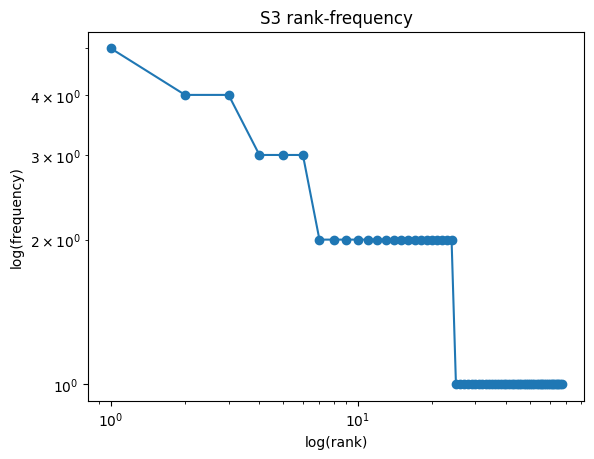

Top 5 bigrams S1: [(('.', 'the'), 4), (('the', 'same'), 4), (('same', 'problem'), 4), (('problem', 'occurs'), 4), (('occurs', 'again'), 4)]
Top 5 bigrams S3: [(('problem', 'occurs'), 4), (('since', 'yesterday'), 2), (('could', "n't"), 2), (("n't", 'connect'), 2), (('resetting', 'password'), 2)]


In [9]:
from collections import Counter
from nltk import bigrams
from nltk.stem import PorterStemmer
import matplotlib.pyplot as plt

R  = [process_ticket(t) for t in df.Ticket_Text]
S1 = [w for r in R for w in r["tokens"]]
S2 = [w for w in S1 if not is_punct(w)]
S3 = [w for r in R for w in r["final"]]
ps = PorterStemmer()
S4 = [ps.stem(w) for w in S3]

display(pd.DataFrame([(n, len(s), len(set(s)), len(set(s)) / len(s))
                      for n, s in zip(["S1", "S2", "S3", "S4"], [S1, S2, S3, S4])],
                     columns=["Set", "Total", "Unique", "TTR"]))

print("Top 10 S1:", Counter(S1).most_common(10))
print("Top 10 S3:", Counter(S3).most_common(10))

freq = sorted(Counter(S3).values(), reverse=True)
plt.loglog(range(1, len(freq) + 1), freq, "o-")
plt.xlabel("log(rank)"); plt.ylabel("log(frequency)"); plt.title("S3 rank-frequency")
plt.show()

for name, key in [("S1", "tokens"), ("S3", "final")]:
    print(f"Top 5 bigrams {name}:", Counter(b for r in R for b in bigrams(r[key])).most_common(5))

## Q6. Interpretation

Answer briefly:

**(a)** Why does TTR change from S1 to S4 in your dataset?

**(b)** Give one example where `word_tokenize()` and your tokenizer differ. Explain the difference.

**(c)** Give one example where stemming produces an undesirable result.

**(d)** Give one example where POS-aware lemmatization preserves meaning better than stemming.

---

### Answers

**(a)** TTR (unique ÷ total) rises from S1 (`___`) to S2 (`___`) to S3 (`___`). The tickets repeat the same punctuation (`.`, `,`) and stopwords (`the`, `is`, `it`) many times, which inflate the total count but add few unique types. Removing them shrinks the total much more than the unique count, so the ratio goes up. From S3 to S4, Porter stemming merges variants such as `changed` and `change`. The total stays the same but the unique count drops, so TTR falls slightly (`___` → `___`). Overall, S4 still has a higher TTR than S1.

**(b)** For `isn't`, my tokenizer gives `isn't` as one token, because the pattern allows an apostrophe between word characters. `word_tokenize()` gives `is` and `n't`, because it follows Penn Treebank rules and splits the negation into its own token. My tokenizer preserves the surface form, while `word_tokenize()` separates the negation, which is useful for downstream NLP.

**(c)** Porter turns `resolve` into `resolv` and `update` into `updat`. These stems are not real words and are hard to read. `solution` becomes `solut`, which also loses its meaning.

**(d)** For `changed`, Porter gives `chang`, which is not a word. The POS-aware lemmatizer tags it as a verb and returns `change`, a valid dictionary word with the right meaning.